In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/cdn_logs_july2026.csv", parse_dates=["timestamp"])
df["date"] = df["timestamp"].dt.date
print(df.shape)
df.head()

(930000, 8)


,timestamp,region,customer_id,status_code,latency_ms,cache_status,bytes_sent,date
0,2026-07-01 00:00:01,sa-east,cust_014,200,32.7,HIT,1630833,2026-07-01
1,2026-07-01 00:00:08,eu-west,cust_006,200,37.4,HIT,1795611,2026-07-01
2,2026-07-01 00:00:09,ap-south,cust_014,200,47.9,HIT,424948,2026-07-01
3,2026-07-01 00:00:12,ap-south,cust_006,200,73.0,HIT,204995,2026-07-01
4,2026-07-01 00:00:12,us-west,cust_020,200,408.5,MISS,1573014,2026-07-01


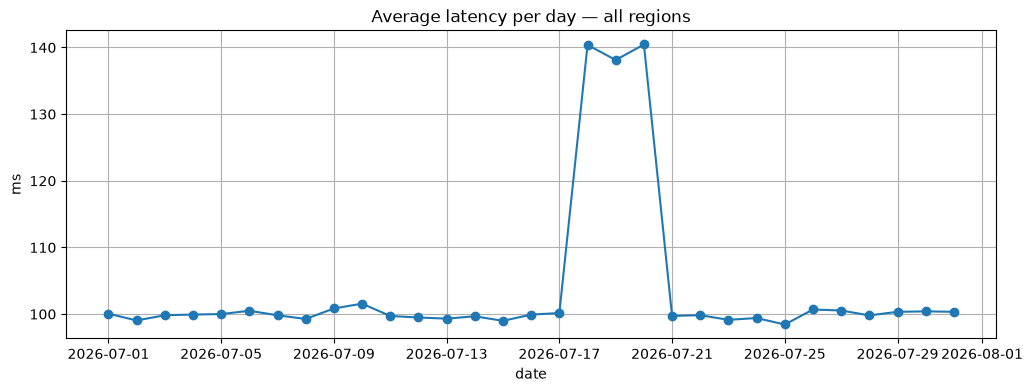

In [2]:
daily = df.groupby("date")["latency_ms"].mean()

plt.figure(figsize=(12, 4))
daily.plot(marker="o")
plt.title("Average latency per day — all regions")
plt.ylabel("ms")
plt.grid(True)
plt.show()

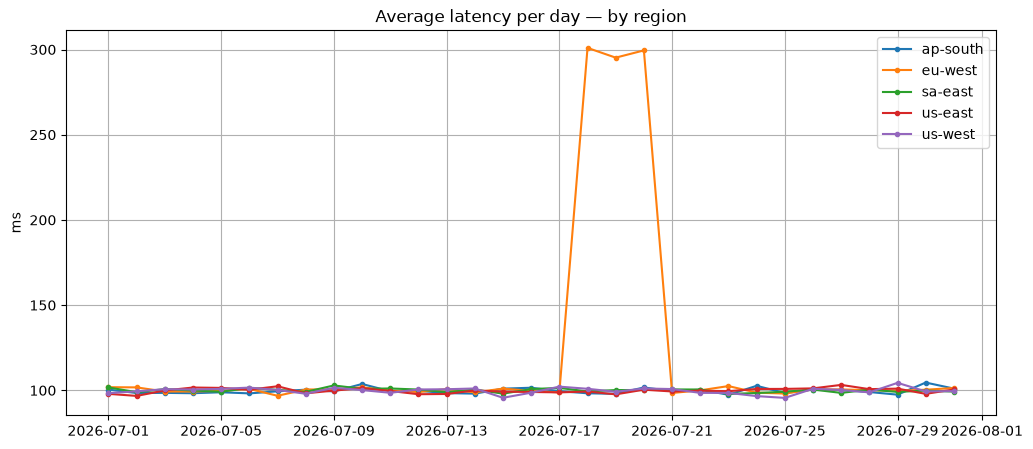

In [3]:
by_region = df.groupby(["date", "region"])["latency_ms"].mean().unstack()

plt.figure(figsize=(12, 5))
for col in by_region.columns:
    plt.plot(by_region.index, by_region[col], marker=".", label=col)
plt.title("Average latency per day — by region")
plt.ylabel("ms")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
incident = df[(df["region"] == "eu-west")]
incident_days = incident[incident["date"].astype(str).isin(["2026-07-18", "2026-07-19", "2026-07-20"])]
normal_days   = incident[~incident["date"].astype(str).isin(["2026-07-18", "2026-07-19", "2026-07-20"])]

print(f"eu-west normal:   avg {normal_days['latency_ms'].mean():.1f} ms | p95 {normal_days['latency_ms'].quantile(0.95):.1f} ms")
print(f"eu-west incident: avg {incident_days['latency_ms'].mean():.1f} ms | p95 {incident_days['latency_ms'].quantile(0.95):.1f} ms")
print(f"impact multiplier: {incident_days['latency_ms'].mean() / normal_days['latency_ms'].mean():.2f}x")

eu-west normal:   avg 100.0 ms | p95 353.5 ms
eu-west incident: avg 298.6 ms | p95 1051.4 ms
impact multiplier: 2.98x


In [5]:
hit_rate_incident = (incident_days["cache_status"] == "HIT").mean() * 100
hit_rate_normal   = (normal_days["cache_status"] == "HIT").mean() * 100
print(f"cache hit rate — normal: {hit_rate_normal:.1f}% | incident: {hit_rate_incident:.1f}%")

# were HITs themselves slower during the incident?
hits_incident = incident_days[incident_days["cache_status"] == "HIT"]["latency_ms"].mean()
hits_normal   = normal_days[normal_days["cache_status"] == "HIT"]["latency_ms"].mean()
print(f"HIT latency — normal: {hits_normal:.1f} ms | incident: {hits_incident:.1f} ms")

cache hit rate — normal: 80.0% | incident: 80.1%
HIT latency — normal: 50.0 ms | incident: 149.7 ms
